Using cpu device
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 94.2     |
|    ep_rew_mean     | -290     |
| time/              |          |
|    episodes        | 4        |
|    fps             | 80       |
|    time_elapsed    | 4        |
|    total_timesteps | 377      |
| train/             |          |
|    actor_loss      | 0.741    |
|    critic_loss     | 69.3     |
|    ent_coef        | 0.924    |
|    ent_coef_loss   | -0.228   |
|    learning_rate   | 0.0003   |
|    n_updates       | 276      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 126      |
|    ep_rew_mean     | -262     |
| time/              |          |
|    episodes        | 8        |
|    fps             | 67       |
|    time_elapsed    | 14       |
|    total_timesteps | 1005     |
| train/             |          |
|    actor_loss      | 1.23     |
|    critic_loss     | 22.7    

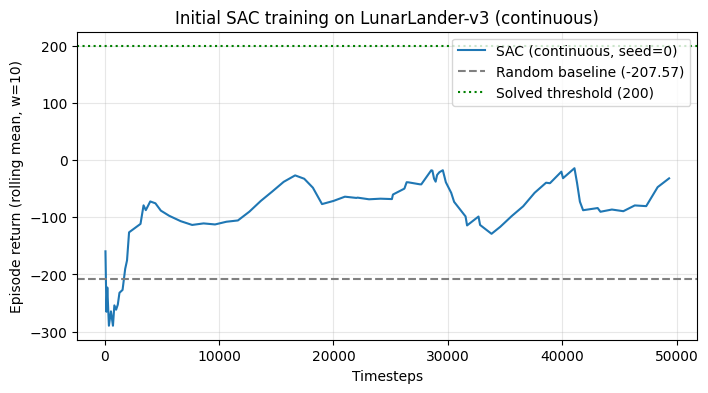

In [10]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
from stable_baselines3.common.monitor import load_results

if "." not in sys.path:
    sys.path.insert(0, ".")

from algorithm_runners.sac import run_sac_scenario

sac_returns = run_sac_scenario(
    space="continuous",
    seed=0,
    total_timesteps=50_000,
    n_eval_episodes=20,
)

# Wykres krzywej uczenia
log_path = Path.cwd() / "logs" / "init_sac_continuous_seed0" / "train"
df = load_results(str(log_path))
timesteps = df["l"].cumsum()
rolling_ret = df["r"].rolling(window=10, min_periods=1).mean()

plt.figure(figsize=(8, 4))
plt.plot(timesteps, rolling_ret, label="SAC (continuous, seed=0)")
plt.axhline(-207.57, color="gray", linestyle="--", label="Random baseline (-207.57)")
plt.axhline(200, color="green", linestyle=":", label="Solved threshold (200)")
plt.xlabel("Timesteps")
plt.ylabel("Episode return (rolling mean, w=10)")
plt.title("Initial SAC training on LunarLander-v3 (continuous)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("init_sac_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
import importlib
from pathlib import Path
import algorithm_runners.sac as sac_mod

importlib.reload(sac_mod)

print("=== Final model (50k) ===")
sac_mod.evaluate_wind_robustness("models/sac_continuous_seed0.zip", seed=0, n_eval_episodes=20)

best_path = Path("models/sac_continuous_seed0_best/best_model.zip")
if best_path.exists():
    print("\n=== Best checkpoint (EvalCallback) ===")
    sac_mod.evaluate_wind_robustness(best_path, seed=0, n_eval_episodes=20)

=== Final model (50k) ===
[SAC Robustness | no_wind] Mean: -14.75 | Std: 24.50 | Success(>=200): 0.0%
[SAC Robustness | with_wind] Mean: -82.33 | Std: 102.05 | Success(>=200): 0.0%

=== Best checkpoint (EvalCallback) ===
[SAC Robustness | no_wind] Mean: -7.18 | Std: 34.42 | Success(>=200): 0.0%
[SAC Robustness | with_wind] Mean: -97.28 | Std: 113.92 | Success(>=200): 0.0%
